<h1 style="text-align:center;">Exploratory Data Analysis on Credit Risk Data</h1>

<h3 style="text-align:center;">Author: Hanna Hajdu</h3>

# Introduction

As the first part of a bigger, more extensive Data Science project with a risk analysis focus, the Exploratory Data Analysis aims to understand the structure and characteristics of the dataset, detect and balance potential data quality issues, identify relevant patterns, and examine relationships between the available variables. 

**Table of contents**<a id='toc0_'></a>    
- 1. [Data overview](#toc1_)    
  - 1.1. [Importing the data and required libraries](#toc1_1_)    
  - 1.2. [Size and structure of the dataset](#toc1_2_)    
  - 1.3. [Variables](#toc1_3_)    
    - 1.3.1. [Target variable](#toc1_3_1_)    
- 2. [Data quality assessment](#toc2_)    
  - 2.1. [Missing values and duplicates](#toc2_1_)    
    - 2.1.1. [Analysis on missingness patterns](#toc2_1_1_)    
    - 2.1.2. [Missing values handling strategy](#toc2_1_2_)    
  - 2.2. [Invalid values](#toc2_2_)    
    - 2.2.1. [Initial validity rules](#toc2_2_1_)    
    - 2.2.2. [Inspecting the impact of and updating the validity criteria](#toc2_2_2_)    
- 3. [Data cleaning and transformation](#toc3_)    
  - 3.1. [Data quality enhancement](#toc3_1_)    
  - 3.2. [Preparing data for analysis](#toc3_2_)    
- 4. [Univariate data analysis](#toc4_)    
  - 4.1. [Descriptive statistical analysis](#toc4_1_)    
  - 4.2. [Outlier assessment](#toc4_2_)    
  - 4.3. [Examining data distribution](#toc4_3_)    
    - 4.3.1. [Distribution of numerical variables](#toc4_3_1_)    
    - 4.3.2. [Distribution of categorical variables](#toc4_3_2_)    
- 5. [Bivariate and multivariate analysis](#toc5_)    
  - 5.1. [Investigating correlation between numerical variables](#toc5_1_)    
    - 5.1.1. [Objective](#toc5_1_1_)    
    - 5.1.2. [Method](#toc5_1_2_)    
    - 5.1.3. [Results](#toc5_1_3_)    
  - 5.2. [Investigating numerical variables in association with categorical variables](#toc5_2_)    
    - 5.2.1. [Objective](#toc5_2_1_)    
    - 5.2.2. [Method](#toc5_2_2_)    
    - 5.2.3. [Results](#toc5_2_3_)    
  - 5.3. [Investigating correlation between categorical variables](#toc5_3_)    
    - 5.3.1. [Objective](#toc5_3_1_)    
    - 5.3.2. [Method](#toc5_3_2_)    
    - 5.3.3. [Results](#toc5_3_3_)    
- 6. [Summary: EDA findings](#toc6_)    
  - 6.1. [Predictive value and optimization potential of loan grades](#toc6_1_)    
  - 6.2. [Default rate differentiating factors and their implications](#toc6_2_)    
  - 6.3. [Next steps to identify actionable insights based on findings](#toc6_3_)    
    - 6.3.1. [Risk segmentation](#toc6_3_1_)    
    - 6.3.2. [Predictive ML model](#toc6_3_2_)    
  - 6.4. [Limitations](#toc6_4_)    
    - 6.4.1. [Missing context and cardinality](#toc6_4_1_)    
    - 6.4.2. [Survivorship bias](#toc6_4_2_)    

<!-- vscode-jupyter-toc-config
	numbering=true
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

# 1. <a id='toc1_'></a>[Data overview](#toc0_)

## 1.1. <a id='toc1_1_'></a>[Importing the data and required libraries](#toc0_)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, kruskal
from scipy.stats.contingency import association

df = pd.read_csv("C:/Users/Felhasználó/Documents/data analysis/risk analysis/data/raw/credit_risk_dataset.csv")

## 1.2. <a id='toc1_2_'></a>[Size and structure of the dataset](#toc0_)

In [16]:
display(df.shape)
display(df.head())

(32581, 12)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


The dataset contains 12 variables and 32581 samples. The 12 column names and their meanings are listed below.

<table>
    <thead>
    <tr>
      <th scope="col">Variable name</th>
      <th scope="col">Meaning</th>
      <th scope="col">Data type</th>
    </tr>
    </thead>
    <tbody>
    <tr>
      <th scope="row">person_age</th>
      <td>Age</td>
      <td>Discrete numerical</td>
    </tr>
    <tr>
      <th scope="row">person_income</th>
      <td>Annual income</td>
      <td>Discrete numerical</td>
    </tr>
    <tr>
      <th scope="row">person_home_ownership</th>
      <td>Home ownership type</td>
      <td>Nominal</td>
    </tr>
    <tr>
      <th scope="row">person_emp_length</th>
      <td>Employment length (in years)</td>
      <td>Discrete numerical</td>
    </tr>
    <tr>
      <th scope="row">loan_intent</th>
      <td>Loan intent</td>
      <td>Nominal</td>
    </tr>
    <tr>
      <th scope="row">loan_grade</th>
      <td>Loan grades from A to G</td>
      <td>Ordinal</td>
    </tr>
    <tr>
      <th scope="row">loan_amnt</th>
      <td>Loan amount</td>
      <td>Discrete numerical</td>
    </tr>
    <tr>
      <th scope="row">loan_int_rate</th>
      <td>Interest rate</td>
      <td>Continuous</td>
    </tr>
    <tr>
      <th scope="row">loan_status</th>
      <td>Loan status (0 is non default 1 is default)</td>
      <td>Nominal</td>
    </tr>
    <tr>
      <th scope="row">loan_percent_income</th>
      <td>Loan-to-income ratio</td>
      <td>Continuous</td>
    </tr>
    <tr>
      <th scope="row">cb_person_default_on_file</th>
      <td>Historical default</td>
      <td>Nominal</td>
    </tr>
    <tr>
      <th scope="row">cb_person_cred_hist_length</th>
      <td>Credit history length</td>
      <td>Discrete numerical</td>
    </tr>
    </tbody>
</table>

Looking at the second row of the dataset we can tell that the person was 21 years old with an annual income of 9600 USD. They owned a house and they have been employed for 5 years at the point they requested loan for education. As for their prior financial behaviour, they had 2 years of credit history recorded altogether in which they did not default. Their loan grade was B suggesting lower risk and more trust from the issuing institution. With a loan amount of 1000 USD and interest rate of 11.14%, the loan took up 10% of their salary. They successfully settled the loan and did not default.

## 1.3. <a id='toc1_3_'></a>[Variables](#toc0_)

In [17]:
display(df.describe())
display(df.info())

categorical_cols = df.select_dtypes(include="object").columns
for col in categorical_cols:
    print(f"--- Column: {col} ---")
    print(f"{df[col].unique()} \n")


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


None

--- Column: person_home_ownership ---
['RENT' 'OWN' 'MORTGAGE' 'OTHER'] 

--- Column: loan_intent ---
['PERSONAL' 'EDUCATION' 'MEDICAL' 'VENTURE' 'HOMEIMPROVEMENT'
 'DEBTCONSOLIDATION'] 

--- Column: loan_grade ---
['D' 'B' 'C' 'A' 'E' 'F' 'G'] 

--- Column: cb_person_default_on_file ---
['Y' 'N'] 



After taking a closer look to the dataset with some of the most comprehensive data quality analysis commands, we can gain a deeper understanding of the data we are working with.
The analysis shows that all numerical variables have integer or float datatypes and almost all categorical columns are strings. In order to facilitate calculations with the data, 'N' and 'Y' values in the cb_person_default_on_file column will be encoded as '0' and '1' respectively. Loan_status and cb_person_default_on_file will both be changed to boolean types.

The analysis confirmed that the unique categorical values are consistent and do not contain unknown cells, while 2 numerical columns contain missing data.

Descriptive statistical indicators reveal logical inconsistencies in the data, such as the maximum values of the age column (144 years) and employement length column (123 years). Since these are definitely not valid values, they cannot be considered outliers, therefore this is most probably a data quality concern. In order to ensure an accurate analysis and a well-working ML algorithm, rows containig invalid data need to be removed.

In the data quality assessment we will be taking a closer look on the identified errors and inconsistencies.

In [10]:
df["cb_person_default_on_file"] = df["cb_person_default_on_file"].map({"N": False, "Y": True})
df["loan_status"] = df["loan_status"].astype(bool)

It is worth noting that the minimum value of the loan_percent_income column is 0. A 0 in this column would mean that the loan amount takes up 0% of the person's income. Since every client in this dataset is borrower, this raises a data accuracy problem, which probably comes from the variable being calculated and rounded to 2 decimals, resulting in some information loss in the variable. In order to have an even more accurate data, this column will be recalculated.

In [2]:
df["loan_pct_income"] = df["loan_amnt"] / df["person_income"]
df["difference"] = df["loan_percent_income"] - df["loan_pct_income"]
print(f"Information loss due to rounding: \n{df["difference"].describe()}")

df.drop(columns=["loan_percent_income", "difference"], inplace=True)

Information loss due to rounding: 
count    32581.000000
mean        -0.000350
std          0.004926
min         -0.093382
25%         -0.002500
50%          0.000000
75%          0.002500
max          0.005000
Name: difference, dtype: float64


### 1.3.1. <a id='toc1_3_1_'></a>[Target variable](#toc0_)

The main question that this analysis seeks to answer is 'How can we tell ahead of time, if someone is going to default?' or in data terms 'What features and patterns increase the probability of defaulting, if any?'. There is a column in the dataset that tells us which people ended up defaulting and this is the loan_status column. In order to answer the thesis question, the best course of action would be to explore potential correlations in the data with more emphasis on patterns with the loan_status column. We are also going to train an algorithm to spot these correlations in the data with the target variable being the loan_status column.

In [20]:
print(df["loan_status"].value_counts())
print(df["loan_status"].mean())

loan_status
False    25473
True      7108
Name: count, dtype: int64
0.21816396059052823


The target variable consists of 25473 '0' values and 7108 '1' values, meaning that the classes are imbalanced and the default rate of the dataset is 21.8%. This could impact future analysis reliability and the accuracy of the predictive model, so we will have to keep the imbalance in mind while investigating patterns and evaluating the accuracy of the algorithm.

# 2. <a id='toc2_'></a>[Data quality assessment](#toc0_)

## 2.1. <a id='toc2_1_'></a>[Missing values and duplicates](#toc0_)

In [21]:
print(df.isnull().sum())
display(df[df.duplicated()])

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
loan_pct_income                  0
dtype: int64


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,cb_person_default_on_file,cb_person_cred_hist_length,loan_pct_income
15975,23,42000,RENT,5.0,VENTURE,B,6000,9.99,False,False,4,0.142857
15989,23,90000,MORTGAGE,7.0,EDUCATION,B,8000,10.36,False,False,3,0.088889
15995,24,48000,MORTGAGE,4.0,MEDICAL,A,4000,5.42,False,False,4,0.083333
16025,24,10000,RENT,8.0,PERSONAL,A,3000,7.90,True,False,3,0.300000
16028,23,100000,MORTGAGE,7.0,EDUCATION,A,15000,7.88,False,False,4,0.150000
...,...,...,...,...,...,...,...,...,...,...,...,...
32010,42,39996,MORTGAGE,2.0,HOMEIMPROVEMENT,A,2500,5.42,False,False,12,0.062506
32047,36,250000,RENT,2.0,DEBTCONSOLIDATION,A,20000,7.88,False,False,17,0.080000
32172,49,120000,MORTGAGE,12.0,MEDICAL,B,12000,10.99,False,False,12,0.100000
32259,39,40000,OWN,4.0,VENTURE,B,1000,10.37,False,False,16,0.025000


Since both data analysis and ML algorithms tend to be sensitive to missing values, we need to investigate where and why they may occur and how we can handle them.
Missing values can be identified in 2 columns of the dataset: 2.7% of the employement length column and 9.5% of the loan interest rate column consists of null values.

The reason behind null values being present in the dataset cannot be determined by looking at the data alone and will be considered unknown information. Even though this is not necessarily an issue regarding the quality of the data, null values still need to be replaced with values that the algorithm can also handle. In order to better understand the unknown data, patterns and correlations with missingness will be further investigated in a part focused on missing values.

Due to the limitations that arise from the nature of this dataset, we cannot determine whether identical rows are true duplicates or not. Since duplicates are only observed in 165 rows (~0.5% of the dataset) they will be handled as exact duplicates and will be removed. 

### 2.1.1. <a id='toc2_1_1_'></a>[Analysis on missingness patterns](#toc0_)

Sometimes missingness occurs in patterns, correlating with other factors in the data suggesting an additional meaning to missingness. Handling missing values without assessing this possibility may make our data lose valuable information and become more biased. In order to make a better decision at how to handle missing data in a way that fits the current dataset, this part aims to identify potential patterns with missingness.

In [22]:
missing_sources = {
    "emp_length_missing": "person_emp_length",
    "loan_int_missing": "loan_int_rate",
}
df = df.assign(**{
    flag: df[column].isna()
    for flag, column in missing_sources.items()
})

print("Co-occurrence analysis of missingness")
display(
    pd.crosstab(
        df["emp_length_missing"],
        df["loan_int_missing"],
        normalize="all",
    ).mul(100)
)

profile_agg = {
    "loan_status": ("loan_status", "mean"),
    "person_age": ("person_age", "median"),
    "person_income": ("person_income", "median"),
    "loan_amnt": ("loan_amnt", "median"),
    "loan_percent_income": ("loan_pct_income", "median"),
    "loan_int_rate": ("loan_int_rate", "median"),
    "person_emp_length": ("person_emp_length", "median"),
    "cb_person_cred_hist_length": ("cb_person_cred_hist_length", "median"),
    "cb_person_default_on_file": ("cb_person_default_on_file", "mean"),
}

for flag in missing_sources:
    print(f"Profiles by {flag}")
    display(df.groupby(flag).agg(**profile_agg))

categorical_cols = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
]

for flag in missing_sources:
    print(f"Missing-data distribution by {flag}")
    for column in categorical_cols:
        display(
            pd.crosstab(df[column], df[flag], normalize="index").mul(100)
        )

Co-occurrence analysis of missingness


loan_int_missing,False,True
emp_length_missing,,
False,87.897855,9.355146
True,2.538289,0.208711


Profiles by emp_length_missing


,loan_status,person_age,person_income,loan_amnt,loan_percent_income,loan_int_rate,person_emp_length,cb_person_cred_hist_length,cb_person_default_on_file
emp_length_missing,,,,,,,,,
False,0.215426,26.0,56000.0,8000.0,0.147115,10.99,4.0,4.0,0.177649
True,0.315084,25.0,36000.0,6000.0,0.166667,9.91,NaN,4.0,0.129609


Profiles by loan_int_missing


,loan_status,person_age,person_income,loan_amnt,loan_percent_income,loan_int_rate,person_emp_length,cb_person_cred_hist_length,cb_person_default_on_file
loan_int_missing,,,,,,,,,
False,0.219379,26.0,55000.0,8000.0,0.147929,10.99,4.0,4.0,0.176922
True,0.206675,26.0,55640.0,8000.0,0.150000,NaN,4.0,4.0,0.170732


... (4 outputs left out)

Missing-data distribution by loan_int_missing


loan_int_missing,False,True
person_home_ownership,,
MORTGAGE,90.166617,9.833383
OTHER,87.850467,12.149533
OWN,91.176471,8.823529
RENT,90.556974,9.443026


loan_int_missing,False,True
loan_intent,,
DEBTCONSOLIDATION,90.234075,9.765925
EDUCATION,90.717496,9.282504
HOMEIMPROVEMENT,91.262136,8.737864
MEDICAL,89.787514,10.212486
PERSONAL,90.816881,9.183119
VENTURE,90.103165,9.896835


loan_int_missing,False,True
loan_grade,,
A,90.693143,9.306857
B,89.895704,10.104296
C,90.244658,9.755342
D,91.395477,8.604523
E,91.390041,8.609959
F,88.796680,11.203320
G,92.187500,7.812500


The co-occurrence analysis of missing details shows only 0.2% of joint missingness in the data, suggesting that the occurrence of missing data is mostly separate across the two examined variables.

The missingness of loan_int_rate does not appear to be strongly associated with the target variable or the examined numerical profiles of the borrowers. On the other hand, employment length missingness shows a noticeable association with some of the observed characteristics of the applicants. Borrowers with missing values have lower median incomes and median loan amounts, while their loan-to-income ratios are slightly higher, and their default rates are also significantly higher. The results support our initial assumption that the missingness may contain information and should not be treated as completely random.

As for the categorical variables, employment length missingness appears to vary across home ownership categories, with the highest missingness rate observed among applicants with OWN home ownership. In contrast, missingness rates are relatively similar across loan intent categories and show smaller differences across the other categorical variables examined. Loan interest rate missingness does not show a strong or consistent relationship with the categorical variables examined.

### 2.1.2. <a id='toc2_1_2_'></a>[Missing values handling strategy](#toc0_)

When it comes to this specific dataset removing rows with missing information is not a viable option, replacing them would be much more preferable.

Since missing interest rates take up about 9.6% of the observations, removing them could lead to a data loss potentially more harmful to predictive accuracy than imputation. Although imputation reduces the variance of the data, the significance of these values justifies the usage of this method.

During the assessment of the missing data in the employment length column, an underlying pattern surfaced, suggesting that missingness itself carries additional information. The missing values cannot be left empty, therefore median imputation will be performed on this column as well. In order to keep the information that lies behind missingness, the boolean emp_length_missing column (previously used to identify missingness patterns) will be kept to flag values that were originally missing. 

Although the above mentioned strategy is preferred for the purposes of the algorithm, in the aspect of the data analysis, filling the missing values with artificial data might lead to inaccurate insights. Therefore this step will only be done when building the model, missing values here will be handled with code that ignores nans.

## 2.2. <a id='toc2_2_'></a>[Invalid values](#toc0_)

### 2.2.1. <a id='toc2_2_1_'></a>[Initial validity rules](#toc0_)

Invalid values raise a great data quality concern, therefore age and employment length values above a reasonable threshold will also be removed as a next step. Additionally, data that proves to be inaccurate by respective values in the other column (e.g. higher employment length than age) will also be removed.
Assuming that no borrower is past 100 years old and that no borrower started working or received loans before the age of 16, the validity criteria will be the following:

* person_age < 100
* person_emp_length < person_age – 16
* cb_person_cred_hist_length < person_age – 16 

In [4]:
invalid_age = df["person_age"] > 100
invalid_emp = df["person_emp_length"] > df["person_age"]-16 
invalid_hist =df["cb_person_cred_hist_length"]> df["person_age"]-16

print(f"Number of invalid ages: {invalid_age.sum()}")
print(f"Number of invalid employment lengths: {invalid_emp.sum()}")
print(f"Number of invalid credit history lengths: {invalid_hist.sum()}")

Number of invalid ages: 5
Number of invalid employment lengths: 740
Number of invalid credit history lengths: 0


### 2.2.2. <a id='toc2_2_2_'></a>[Inspecting the impact of and updating the validity criteria](#toc0_)

The vast majority of the data deemed logically inconsistent is caused by violating the employment length validity rule. This could be due to the strictness of the initially set validity criterium. Let's investigate how this data is distributed now. 

In [5]:
df["employment_excess"] = (df["person_emp_length"] - (df["person_age"] - 16))
df.loc[invalid_emp, "employment_excess"].describe(percentiles=[0.9, 0.95, 0.99])

count    740.000000
mean       1.314865
std        6.052503
min        1.000000
50%        1.000000
90%        1.000000
95%        1.000000
99%        1.000000
max      118.000000
Name: employment_excess, dtype: float64

Since the majority of the data fell short of the validity criteria by only one year, it is worth investigating what difference a little bit more flexible principle would make.

In [25]:
invalid_emp_new = df["person_emp_length"] > df["person_age"]-15
print(f"Number of invalid employment lengths with starting age 15: {invalid_emp_new.sum()}")

Number of invalid employment lengths with starting age 15: 2


The results suggest that loosening the standard with just 1 year would lead to significantly less data loss. Since starting work at the age of 15 can also be reasonable, the validity criterium will be updated to the following:

* person_age < 100
* person_emp_length < person_age – 15
* cb_person_cred_hist_length < person_age – 16 

# 3. <a id='toc3_'></a>[Data cleaning and transformation](#toc0_)

## 3.1. <a id='toc3_1_'></a>[Data quality enhancement](#toc0_)

Data cleaning will be conducted in the following order:

1. Removing duplicates

    Since duplicates represent only a small number of records, removing them will not affect the size of the dataset greatly. For reasons of avoiding the risks that exact duplicates may hold, the first step will be removing these rows.

2. Removing invalid values

Carrying these two steps out will result in minimal data loss, however, this trade-off is necessary in order to enhance the reliability and accuracy of the analytic and predictive results.


In [ ]:
# New variable on which the cleaning will be done
df_clean = df.drop(columns=["employment_excess"]).copy()
print(f"Dimensions of the data pre-cleaning: {np.shape(df_clean)}")

# Removing duplicate rows
df_clean = df_clean.drop(index=df_clean.index[df_clean.duplicated()])
print(f"Dimensions after removing duplicates: {np.shape(df_clean)}")

# Removing invalid values
invalid_flag = (df_clean["person_age"] > 100) | (df_clean["person_emp_length"] > df_clean["person_age"]-15) | (df_clean["cb_person_cred_hist_length"]> df_clean["person_age"]-16)
df_clean = df_clean.drop(index=df_clean.index[invalid_flag])
print(f"Dimensions after removing invalid values: {np.shape(df_clean)}")

#Saving the cleaned data to a new CSV file
df_clean.to_csv("C:/Users/Felhasználó/Documents/data analysis/credit-risk-analysis/risk analysis/data/credit_risk_dataset_cleaned.csv", index=False)

Dimensions of the data pre-cleaning: (32581, 12)
Dimensions after removing duplicates: (32416, 12)
Dimensions after removing invalid values: (32409, 12)


## 3.2. <a id='toc3_2_'></a>[Preparing data for analysis](#toc0_)

As different data types require different analysis methods, we need to be able to choose the right subset of the data for the task at hand in the future. Sorting the data into python variables based on their type will facilitate data selection when the analysis starts. While boolean and categorical values are handled as different by the coding environment, we often have to handle them both as categorical variables, so there will be a new cat_bool_cols variable that contains both data.

In [12]:
numeric_cols = df_clean.select_dtypes(include="number")
categorical_cols = df_clean.select_dtypes(include="object")
binary_cols = df_clean.select_dtypes(include="bool")
cat_bool_cols = categorical_cols.columns.append(binary_cols.columns)

# 4. <a id='toc4_'></a>[Univariate data analysis](#toc0_)

## 4.1. <a id='toc4_1_'></a>[Descriptive statistical analysis](#toc0_)

In [28]:
num_describe = numeric_cols.describe().apply(lambda s: s.apply("{0:.5f}".format))
num_describe = num_describe.T
num_describe["range"] = numeric_cols.max() - numeric_cols.min()
num_describe["mean_median_difference"] = numeric_cols.mean() - numeric_cols.median()
num_describe["skewness"] = numeric_cols.skew()
num_describe = num_describe.T

display(num_describe)


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,cb_person_cred_hist_length,loan_pct_income
count,32409.00000,32409.00000,31522.00000,32409.00000,29315.00000,32409.00000,32409.00000
mean,27.73075,65894.27705,4.78285,9592.48665,11.01710,5.81119,0.17060
std,6.21045,52517.86997,4.03734,6320.88513,3.24172,4.05790,0.10705
min,20.00000,4000.00000,0.00000,500.00000,5.42000,2.00000,0.00079
25%,23.00000,38500.00000,2.00000,5000.00000,7.90000,3.00000,0.08972
50%,26.00000,55000.00000,4.00000,8000.00000,10.99000,4.00000,0.14815
75%,30.00000,79200.00000,7.00000,12250.00000,13.47000,8.00000,0.22917
max,94.00000,2039784.00000,41.00000,35000.00000,23.22000,30.00000,0.83000
range,74.0,2035784.0,41.0,34500.0,17.8,28.0,0.829211
mean_median_difference,1.730754,10894.277053,0.78285,1592.486655,0.027099,1.811194,0.022448


The table of descriptive statistics above summarizes the main features of the dataset after cleaning. These features include central tendency, variability and skewness. According to the skewness values loan_int_rate seems to be normally distributed, while all other numerical columns are likely strongly skewed. The differences between the mean and median values suggest that the mentioned columns are right-skewed.

The max values reveal data that seem to highly deviate from the respective central values, suggesting the presence of outliers that may play a role in the asymmetry of the data distribution. 

In [29]:
display(categorical_cols.describe())

bool_describe = pd.DataFrame({
    "count": binary_cols.count(),
    "mean": binary_cols.mean()
})
display(bool_describe.transpose())

,person_home_ownership,loan_intent,loan_grade
count,32409,32409,32409
unique,4,6,7
top,RENT,EDUCATION,A
freq,16374,6409,10702


,loan_status,cb_person_default_on_file
count,32409.000000,32409.000000
mean,0.218705,0.176772


The frequencies of categories also point at a potential disproportionate distribution in the person_home_ownership and loan_grade columns. Visualizing the distribution of these columns will be needed to identify class imbalances more accurately and more easily.

## 4.2. <a id='toc4_2_'></a>[Outlier assessment](#toc0_)

Extreme values - while carrying relevant information - highly and disproportionately impact the statistical characteristics of the data, which needs to be taken into account while performing a deeper analysis. Let's discover and summarize the outliers in the numerical variables with the IQR method. 

* Q1 = 1st quantile
* Q3 = 3rd quantile
* IQR = Q3 - Q1
* Lower limit (values below will be returned as outliers): Q1 - 1.5 * IQR
* Upper limit (values above will be returned as outliers): Q3 + 1.5 * IQR

It is important to note, that impossibly high values would also be returned as statistical outliers. The structure of the notebook seeks to prevent this by ensuring that recognized invalid values were already removed from the data by this point in the analysis.

In [13]:
Q1 = numeric_cols.quantile(.25, axis = 0)
Q3 = numeric_cols.quantile(.75, axis = 0)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers_list = []

for col in numeric_cols.columns:
    for idx, value in numeric_cols[col].items():
        if value < lower_limit[col] or value > upper_limit[col]:
            outliers_list.append({"row": idx, "column": col, "value": value})

outliers_iqr = pd.DataFrame(outliers_list).set_index("row")

outlier_summary = outliers_iqr.groupby("column").agg(
    count=("value", "count"),
    min_outlier=("value", "min"),
    max_outlier=("value", "max")
)

outliers_pct_list = []

for col in numeric_cols.columns:
    pct = outlier_summary.loc[col]["count"] / numeric_cols[col].count() * 100
    outliers_pct_list.append({"idx": col, "pct": pct, "upper_limit": upper_limit[col]})

outliers_pct = pd.DataFrame(outliers_pct_list).set_index("idx")
outlier_summary = pd.concat([outlier_summary, outliers_pct], axis = 1)

display(outlier_summary)

print(f"Total number of outliers: {outliers_iqr.index.nunique()}")
print(f"Total percentage of outliers: {outliers_iqr.index.nunique() / len(numeric_cols) * 100:.2f}%")

,count,min_outlier,max_outlier,pct,upper_limit
cb_person_cred_hist_length,1138,16.000000,30.00,3.511370,15.500000
loan_amnt,1678,23200.000000,35000.00,5.177574,23125.000000
loan_int_rate,6,22.060000,23.22,0.020467,21.825000
loan_pct_income,732,0.438356,0.83,2.258632,0.438333
person_age,1486,41.000000,94.00,4.585146,40.500000
person_emp_length,850,15.000000,41.00,2.696529,14.500000
person_income,1474,140300.000000,2039784.00,4.548119,140250.000000


Total number of outliers: 5576
Total percentage of outliers: 17.21%


Judging by the minimums, all values returned as outliers surpassed the upper_limit of the IQR method, suggesting that these values contribute to skewing the data to the right. Extreme values take up between 2.3% and 5.1% of strongly skewed columns. There is no evidence indicating the inaccuracy of these values, therefore their removal would lead to the loss of potentially relevant information. However, if not removed, extreme values run the risk of distorting indicators and certain visualisations, while also adversely affecting the accuracy of statistical methods and machine learning algorithms. 

In order to balance these negative effects, data skewness will be taken into account while choosing further analysis methods and outliers will be capped in impacted visualisations.

As for decreasing the impact of deviating values and skewness on the model's performance, skewed columns will be transformed and columns that only contain a few extremes will be capped in the data used for training the algorithm.

## 4.3. <a id='toc4_3_'></a>[Examining data distribution](#toc0_)

### 4.3.1. <a id='toc4_3_1_'></a>[Distribution of numerical variables](#toc0_)

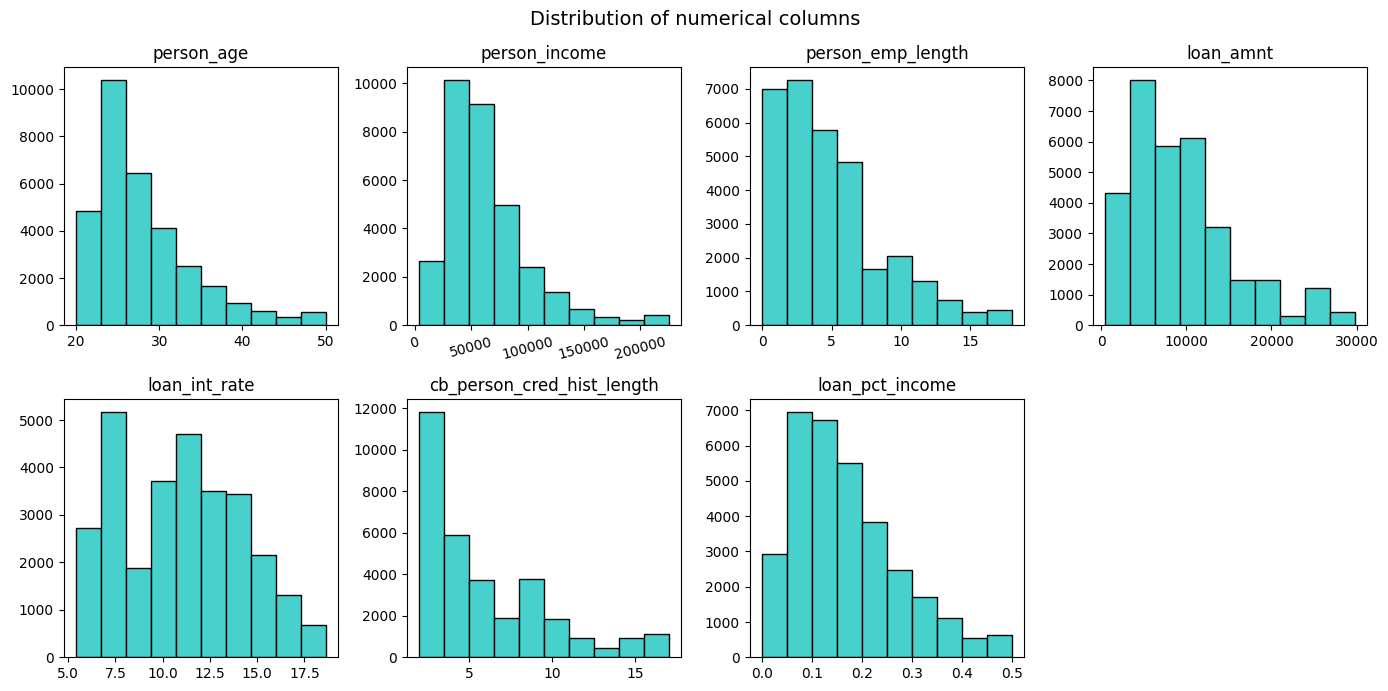

In [106]:
capped = pd.DataFrame(columns = df_clean.columns)
for col in df_clean.columns:
    if col in numeric_cols.columns:
        values = numeric_cols[col].to_numpy(dtype=float, na_value=np.nan)
        upper = np.nanquantile(values, 0.99)
        capped[col] = np.clip(values, a_min=None, a_max=upper)
    else:
        capped[col] = df_clean[col]

cols = numeric_cols.columns

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()
plt.ticklabel_format(style='plain')

for ax, col in zip(axes, cols):
    ax.hist(capped[col].dropna(), bins=10, color='mediumturquoise', edgecolor='black')
    if col == "person_income":
            ax.tick_params(axis='x', labelrotation=15)
    ax.set_title(col)

for ax in axes[len(cols):]:
    ax.set_visible(False)

fig.suptitle("Distribution of numerical columns", fontsize=14)
plt.tight_layout()
plt.show()

The asymmetrical distribution of the numerical columns is now also visible with the telling signs of the peak observed more on the left (lower values on the x axis) with a longer tail towards the right (higher values on the x axis). There is enough proof suggesting that most of these columns are skewed and contain outliers, so all statistical methods will be chosen to fit the distribution.

### 4.3.2. <a id='toc4_3_2_'></a>[Distribution of categorical variables](#toc0_)

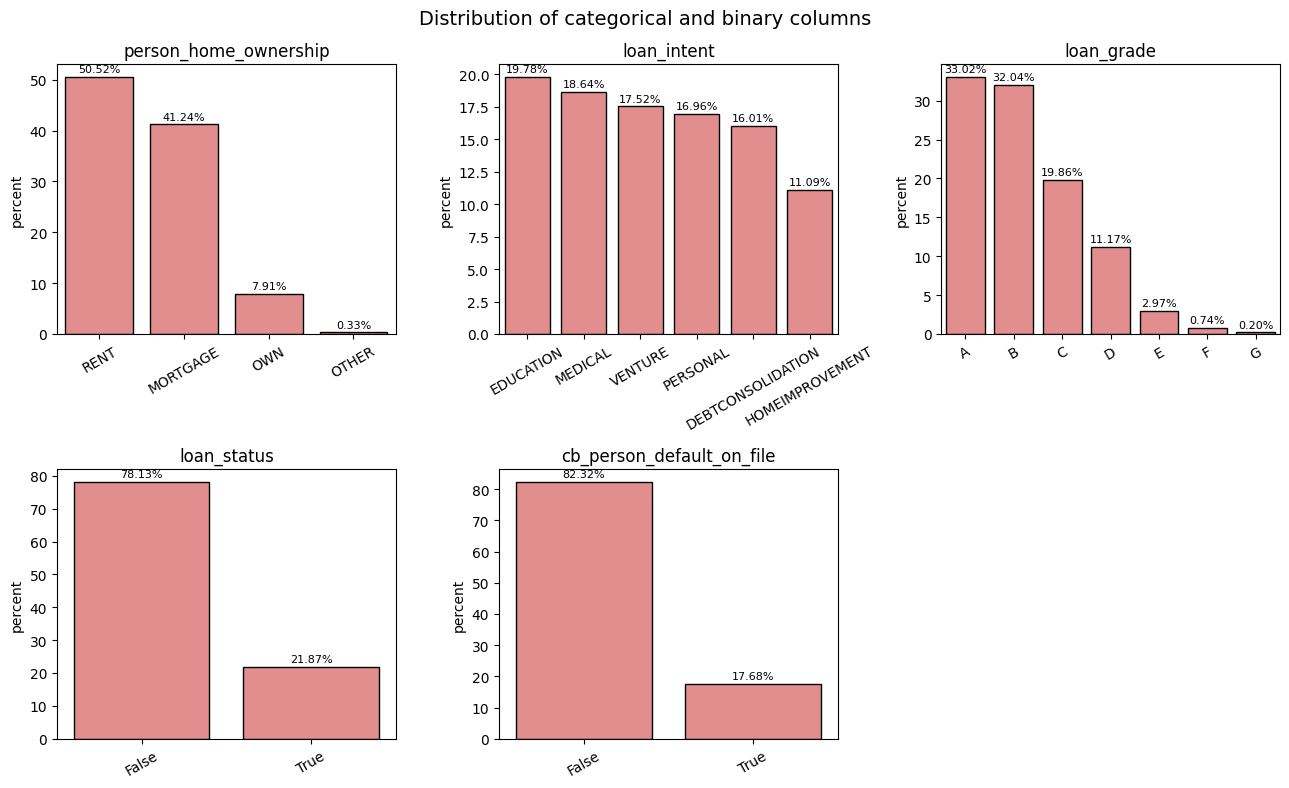

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.flatten()

for ax, col in zip(axes, cat_bool_cols):
    order = df_clean[col].value_counts().index
    sns.countplot(data=df_clean, x=col, order=order, color="lightcoral", edgecolor="black", ax=ax, stat="percent")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelrotation=30)
    ax.bar_label(ax.containers[0], fontsize=8, padding=2, fmt="{:.2f}%")

for ax in axes[len(cat_bool_cols):]:
    ax.set_visible(False)

fig.suptitle("Distribution of categorical and binary columns", fontsize=14)
plt.tight_layout()
plt.show()


The countplots above visualize the percent frequency of each value in the categorical variables, making it easy to spot class imbalances and rare categories. Categorical groups with bigger sample sizes usually mean more reliable results, as they take up a bigger slice of the population. For this reason, any conclusion drawn from rare categories holds uncertainty and the possibility that gathering more data would change the results.

It is worth noting, that some categories are relatively underrepresented within the dataset, such as values 'OWN' and 'OTHER' in the person_home_ownership column and the 'True' group (people with a default history) in the cb_person_default_on_file column. In the loan_grade column there is a monotone, consistent decrease in the number of records as we go from 'A' to 'G', resulting in very few observations in the 'E', 'F' and 'G' categories. This means that patterns discovered in these categories will need to be analysed more carefully than in other, more represented cases.

As for the machine learning model, rare categories can make the algorithm less reliable, so they will be handled differently while building the model.

# 5. <a id='toc5_'></a>[Bivariate and multivariate analysis](#toc0_)

All bivariate analyses will be preceded by a statistical method that shows the strength of the association between relevant variables to identify the most mentionable relationships in the database. This way the bivariate analyses can focus on pairing related variables that proved to have the strongest correlations. 

All methods need to be non-sensitive to skewness and class imbalance, so the chosen methods are Spearman's rank correlation (numerical vs. numerical values), Kruskal-Wallis test with epsilon-squared (categorical vs. numerical values) and Chi-squared test of independence with Cramer's V (categorical vs. categorical values).

**Disclaimer:** These methods can uncover hidden correlations between variables, but do not offer sufficient evidence to verify causational relationships. Any assumption of causation is made with time precedence and correlation in mind, but cannot be confirmed to be more than correlation with strictly the methods and data at hand.

## 5.1. <a id='toc5_1_'></a>[Investigating correlation between numerical variables](#toc0_)

### 5.1.1. <a id='toc5_1_1_'></a>[Objective](#toc0_)

Examine pairwise relationships between numerical variables and identify the strongest correlations.

### 5.1.2. <a id='toc5_1_2_'></a>[Method](#toc0_)

Due to the skewed distribution in numerical columns, a non-parametric approach is required to accurately analyze the association between the variables. Spearman's rank correlation was built to handle this type of distribution well, thus it matches the data. Since at this sample size all correlations with relevant strength would be significant, the correlation coefficient rho (-1 ≤ ρ ≤  1) will be shown, as it provides information on the strength and direction of the associations.

Strength of correlation criteria used (absolute values):
* ρ ≥ 0.20 = weak
* ρ ≥ 0.40 = moderate
* ρ ≥ 0.60 = strong
* ρ ≥ 0.80 = very strong

Text(0.5, 1.0, 'Strength of association between numerical variables')

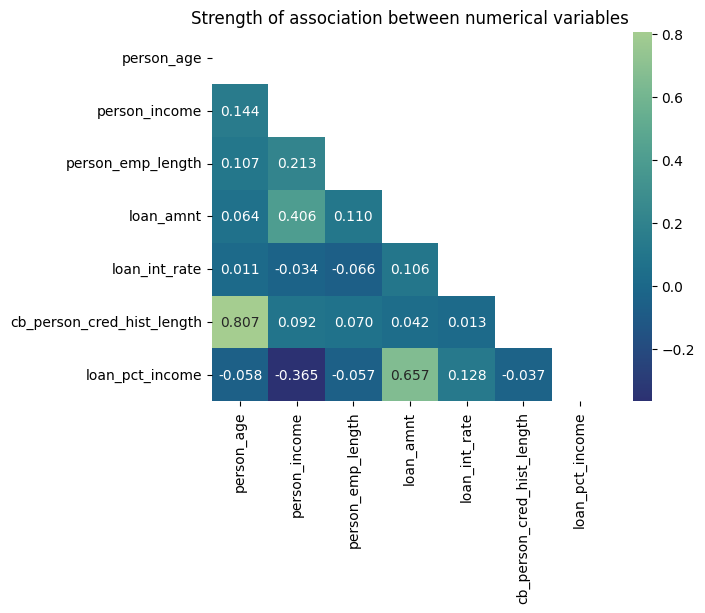

In [33]:
num_correlation = numeric_cols.corr(method="spearman")
sns.heatmap(num_correlation, annot=True, fmt=".3f", cmap="crest_r", mask=np.triu(num_correlation))
plt.title("Strength of association between numerical variables")

### 5.1.3. <a id='toc5_1_3_'></a>[Results](#toc0_)

Spearman's rank correlation between all numerical variables reveals a very strong, monotonic correlation between cb_person_cred_hist_length and person_age (ρ = 0.807) and a moderate correlation between loan_amnt and person_income (ρ = 0.406). While loan_pct_income also strongly correlates with loan_amnt (ρ = 0.657) and weakly negatively correlates with person_income (ρ = -0.365) as well, these relationships are not independant as loan_pct_income is calculated with these two columns.

Text(0.5, 1.0, 'Age vs. credit history length')

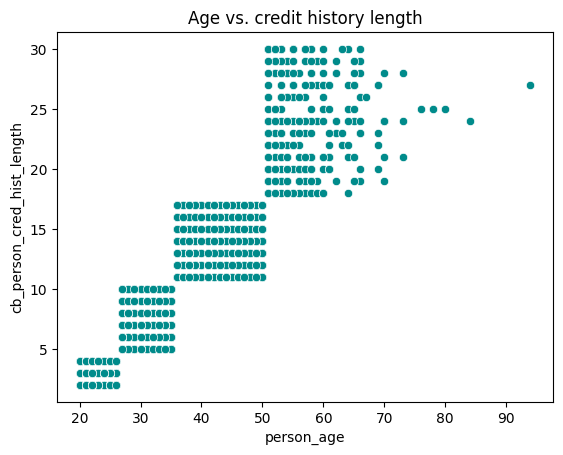

In [34]:
sns.scatterplot(data=df_clean, x="person_age", y="cb_person_cred_hist_length", color="darkcyan")
plt.title("Age vs. credit history length")


Upon looking at the correlation between person_age and credit_history_length more closely, we can tell that older applicants tend to have longer credit histories. This association seems to come from the nature of credit data collection, and as an expected relationship, it should be considered when interpreting models that use both features.

Text(0.5, 1.0, 'Loan amount vs. income')

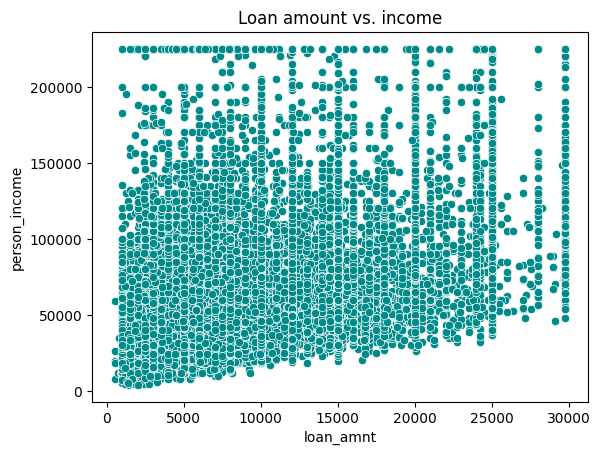

In [35]:
#plt.scatter(capped["loan_amnt"], capped["person_income"], c="darkcyan")
sns.scatterplot(data=capped, x="loan_amnt", y="person_income", color="darkcyan")
plt.ticklabel_format(style='plain')
plt.title("Loan amount vs. income")

According to the scatter plot above, there is an apparent increase in the minimum income values towards higher loan amounts but when it comes to higher incomes, this pattern seems to fall apart. This observation suggests that clients with lower incomes are less likely to receive high loan amounts, implying that loan amounts have a certain minimum income requirement, while indicating more trust towards higher earners. If we assume that high earners are more likely to have the means to settle the loan, higher incomes could indicate less risk. 

## 5.2. <a id='toc5_2_'></a>[Investigating numerical variables in association with categorical variables](#toc0_)

### 5.2.1. <a id='toc5_2_1_'></a>[Objective](#toc0_)

Examine the relationship between numerical and categorical variables.

### 5.2.2. <a id='toc5_2_2_'></a>[Method](#toc0_)

The statistical test for this examination has to be able to work with numerical as well as categorical data with more than 2 groups. Out of the methods that are fit for this purpose, I chose the non-parametric Kruskal-Wallis H test to handle the distributions well. The Kruskal-Wallis H test is significant, if the medians are not the same across all the groups of the categorical variable, but a post-hoc test is needed to see which groups differ. As the statistical analysis here serves as a starting point to see which existing relationships are worth investigating, identifying which groups differ in a strictly statistically significant way is not necessary for us. We are going to focus on the strength of these correlations by calculating epsilon-squared (0 ≤ ε² ≤ 1) from the H values and then examine them further with visualizations.

Strength of correlation thresholds used:
* ε² ≥ 0.04 = moderate
* ε² ≥ 0.16 = relatively strong
* ε² ≥ 0.36 = strong
* ε² ≥ 0.64 = very strong

Text(0.5, 1.0, 'Strength of association between numerical and categorical variables')

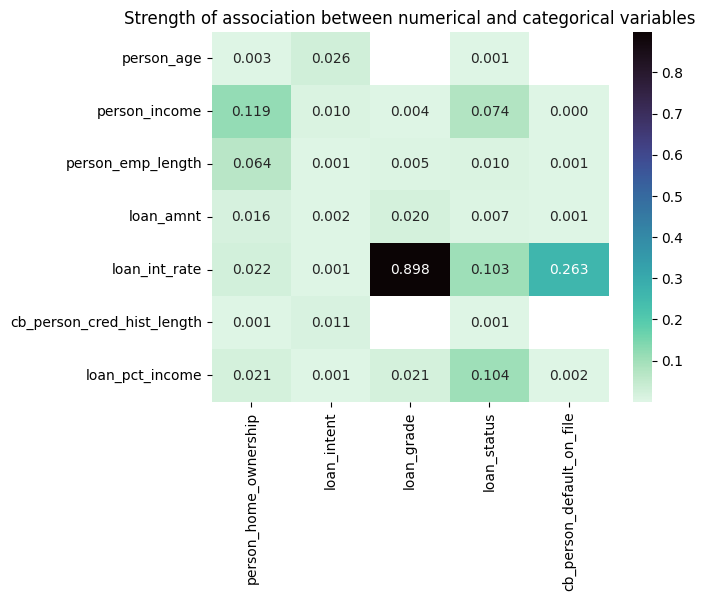

In [36]:
kruskal_results = {}
effect = {}
for cat in cat_bool_cols:
    kruskal_results[cat] = {}
    effect[cat] = {}
    for num in numeric_cols:
        groups = [g[num].dropna().values for _, g in df_clean.groupby(cat)]
        groups = [g for g in groups if len(g) > 0]
        H, p_value = kruskal(*groups)
        kruskal_results[cat][num] = p_value
        n = sum(len(g) for g in groups)
        effect[cat][num] = H / (n - 1)

kruskal_table = pd.DataFrame(kruskal_results)
effect_table = pd.DataFrame(effect)
effect_table = effect_table.mask(kruskal_table > 0.05)
sns.heatmap(effect_table, annot=True, fmt = ".3f", cmap="mako_r")
plt.title("Strength of association between numerical and categorical variables")

### 5.2.3. <a id='toc5_2_3_'></a>[Results](#toc0_)

The epsilon-squared results indicate a very strong association between loan_grade and loan_int_rate (ε²=0.898), a relatively strong association between cb_person_default_on_file and loan_int_rate (ε²=0.263) and moderate associations between person_home_ownership and person_income (ε²=0.119), loan_status and loan_pct_income (ε²=0.104), loan_status and loan_int_rate (ε²=0.103), loan_status and person_income (ε²=0.074), person_home_ownership and person_emp_length (ε²=0.064).

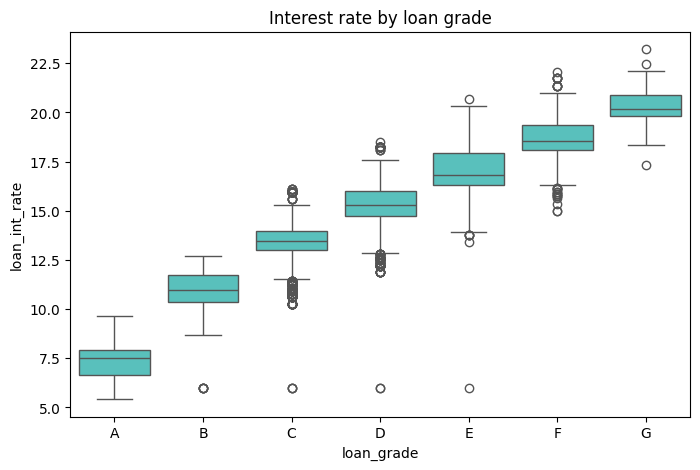

In [55]:
order = sorted(df_clean["loan_grade"].unique())

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df_clean, x="loan_grade", y="loan_int_rate", order=order, color="mediumturquoise", ax=ax)
ax.set_title("Interest rate by loan grade")
plt.show()

The previously concluded strong correlation between loan_int_rate and loan_grade can be observed on this boxplot as well. The consistent and monotonic increase in the interest rate distribution by loan grade is in line with a possible strategic interest rate assignment. Higher interest rates could aim to balance out the risk associated with the loan by increasing the return. Although the small sample sizes in loan grades 'E' to 'G' raise the possibility that the mentioned distribution would change with more data at hand, the correlation is apparent from 'A' to 'D' as well, suggesting that interest rate is indeed tied lo loan grade.

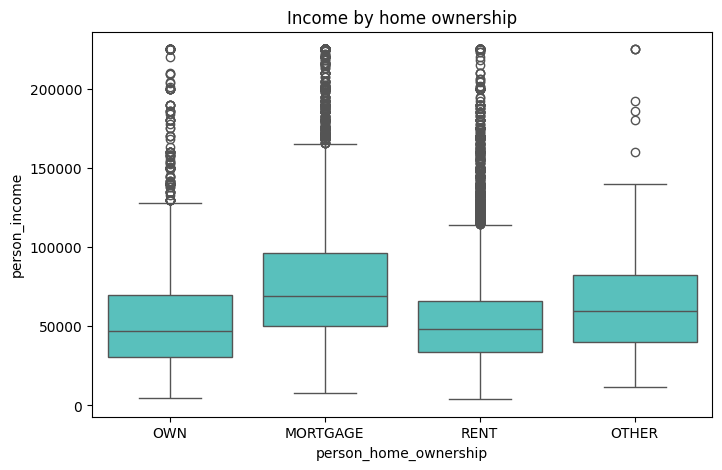

In [38]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=capped, x="person_home_ownership", y="person_income", color="mediumturquoise", ax=ax)
ax.set_title("Income by home ownership")
plt.show()

Looking at the person_income and person_home_ownership relationship - while the minimum data points start at roughly the same amount, meaning that lower incomes appear frequently in all home ownership groups, the same cannot be said about higher incomes. It is noticeable, that there is a bigger variance in the income of clients who pay mortgage, with the inliers covering higher incomes than in other home ownership groups.

The number of high earners in the 'MORTGAGE' group could be explained with bigger financial preparedness in association with the serious and long-term financial commitment required by the mortgage. With more data backing this up, mortgage repayment could be an indicator of financial stability favourable to lenders, while also keeping the financial burden in mind.
However, the minimum values and the variance of the data suggests, that this theory by itself is not a sufficient explanation, leaving room for other interpretations and raising the possibility of another mediating variable. 

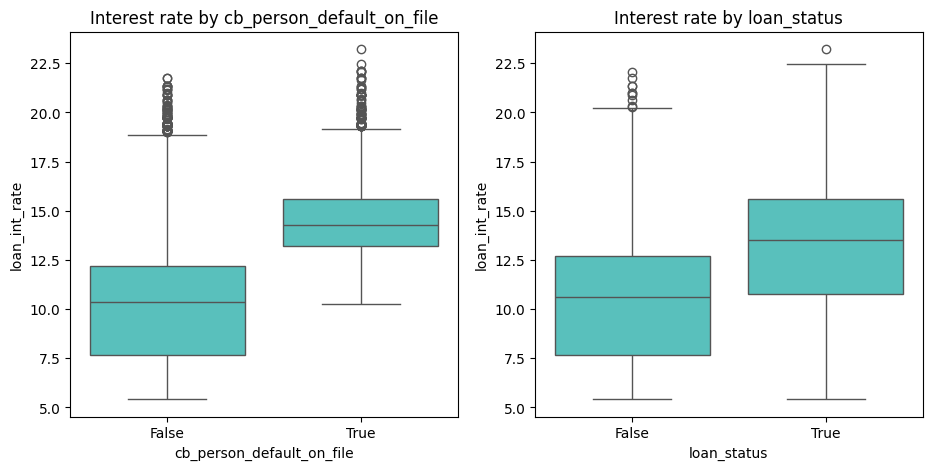

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, col in zip(axes, binary_cols.columns[-1::-1]):
    sns.boxplot(data=df_clean, x=col, y="loan_int_rate", ax=ax, color="mediumturquoise")
    ax.set_title(f"Interest rate by {col}")
plt.show()

While clients with no historical data of defaulting cover a wide range of interest rates, previous defaulters received only higher rates. If we assume that the interest rate decision was influenced by factors that may reflect risk, the correlation above supports that former defaulting can be one of these factors. 

On the other hand, while loan_status also showed correlation with the interest rate, the relationship is not as explicit as seen in the case of cb_person_default_on_file. The range of interest rate values seem to mostly overlap within the 2 loan_status groups. The main difference between the two groups appears in distribution; interest rate among defaulters seems to be close to normal distribution, while interest rate data of non-defaulters is right skewed. This results in a higher central tendency and a slightly higher maximum value of clients who defaulted, meaning that a high interest rate value is a bit more likely to be in the default group than in the non-default group.

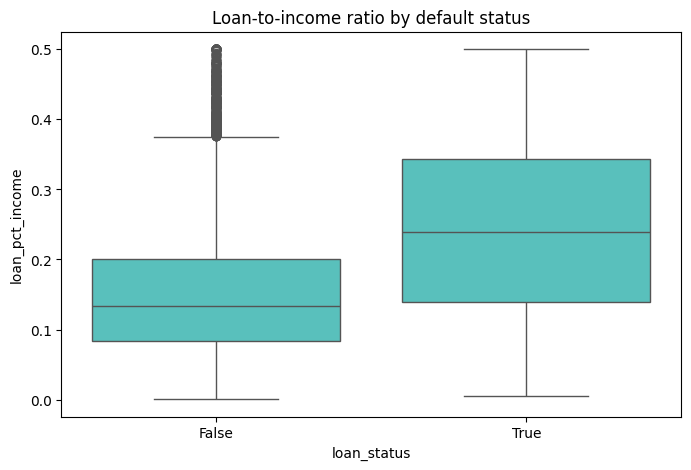

In [40]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=capped, x="loan_status", y="loan_pct_income", color="mediumturquoise", ax=ax)
ax.set_title("Loan-to-income ratio by default status")
plt.show()

The diagram above illustrates the relationship of the loan_status and the loan_pct_income. By the chart we can tell that higher loan_pct_incomes are much more present in the group of clients who ended up defaulting, as these values in the non-default group are considered extreme. This suggests that clients with a higher loan-to-income ratio are more likely to default than not. 

It would be interesting to investigate how this relationship would take shape when examined on a monthly level cashflow with information on loan burden. 

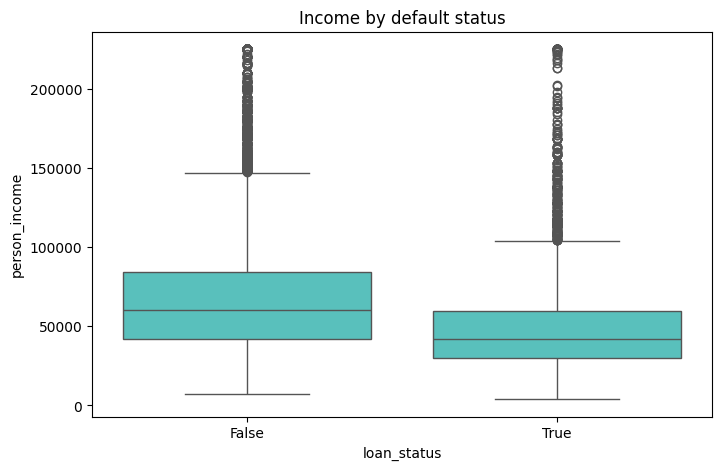

In [41]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=capped, x="loan_status", y="person_income", color="mediumturquoise", ax=ax)
ax.set_title("Income by default status")
plt.show()

This chart shows that people with higher incomes are less likely to default, as defaulters have a lower central tendency and maximum income value, while higher income values are considered rather extreme. 

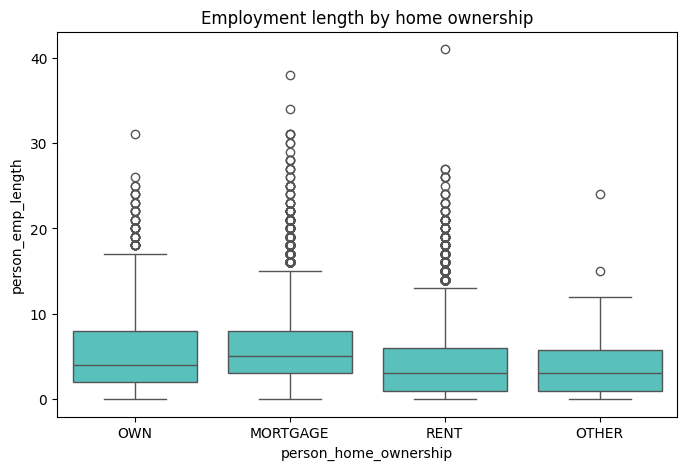

In [42]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=capped, x="person_home_ownership", y="person_emp_length", color="mediumturquoise", ax=ax)
ax.set_title("Employment length by home ownership")
#ax.set_ylim(bottom=None, top=25)
plt.show()

While all groups above contain lower values, longer employment statuses are more present in the homeowner and people in mortgage repayment categories rather than the ones with rent and other housing situations. While this could mean that people with long employments are mostly among people who are prepared to be owners, we need to take into account that 'OWN' and 'OTHER' are rather small groups with less reliability.

## 5.3. <a id='toc5_3_'></a>[Investigating correlation between categorical variables](#toc0_)

### 5.3.1. <a id='toc5_3_1_'></a>[Objective](#toc0_)

Examine the pairwise relationship between categorical variables.

### 5.3.2. <a id='toc5_3_2_'></a>[Method](#toc0_)

A test fit for comparing categorical data with large sample sizes is the Chi-Square Test of Independence with the alternative hypothesis that there is a statistically significant relationship between the variables in question. As significance alone is not sufficiently informative, we will go one step further again and focus on the strength of the correlations where the relationship is significant. The correlation coefficient here will be Cramér's V (0 ≤ *V* ≤ 1), which is closely related to the chi-square.

Strength of correlation thresholds used:
* *V* ≥ 0.10 = weak
* *V* ≥ 0.20 = moderate
* *V* ≥ 0.40 = relatively strong
* *V* ≥ 0.60 = very strong

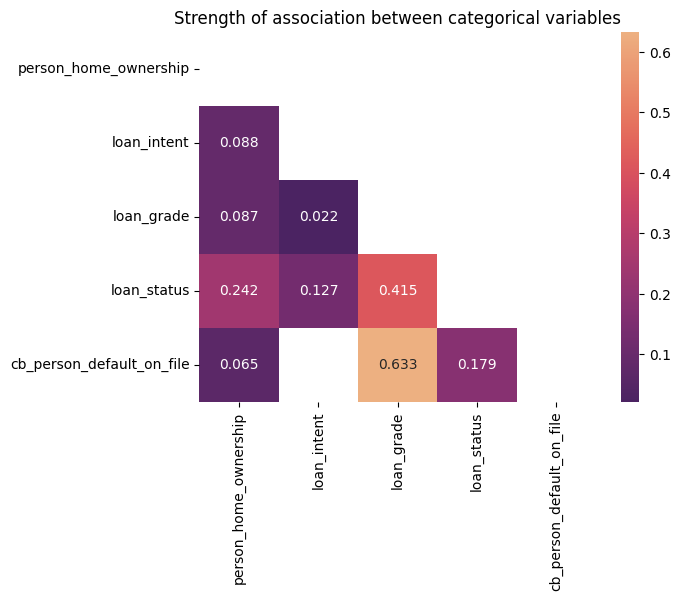

In [43]:
chi_table = pd.DataFrame(index=cat_bool_cols, columns=cat_bool_cols, dtype=float)
cramer_table = pd.DataFrame(index=cat_bool_cols, columns=cat_bool_cols, dtype=float)

for col1 in cat_bool_cols:
    for col2 in cat_bool_cols:
        ct = pd.crosstab(df_clean[col1], df_clean[col2])
        chi_table.loc[col1, col2] = chi2_contingency(ct).pvalue
        cramer_table.loc[col1, col2] = association(ct, method="cramer")

cramer_table = cramer_table.mask(chi_table > 0.05)

sns.heatmap(cramer_table, annot=True, fmt=".3f", cmap="flare_r", mask=np.triu(cramer_table))
plt.title("Strength of association between categorical variables")
plt.show()

### 5.3.3. <a id='toc5_3_3_'></a>[Results](#toc0_)

Results suggest, there is a very strong correlation between loan_grade and cb_person_default_on_file (*V*=0.633), a relatively strong association between loan_grade and loan_status (*V*=0.415) and there is a moderate relationship between person_home_ownership and loan_status (*V*=0.242). 

<Axes: xlabel='loan_grade', ylabel='count'>

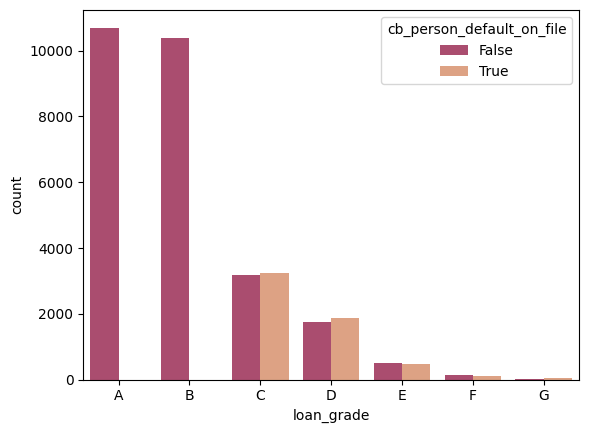

In [44]:
colors = sns.color_palette("flare_r", 12)

sns.countplot(x="loan_grade", hue="cb_person_default_on_file", data=df_clean, order=sorted(df_clean["loan_grade"].unique()), palette=[colors[5], colors[11]])

The data is presented in the form of a countplot, which shows that no person with 'A' or 'B' for loan_grade had 'True' values in cb_person_default_on_file, meaning that clients with lower risk  categories have no historical data of defaulting. This observation could be explained by the assumption that previous defaulters may default again, thus they only qualify for grades with higher risk association. Other grades contain roughly the same amount of clients with a history of defaulting as people with no previous defaulting on record.

<Axes: xlabel='loan_grade', ylabel='count'>

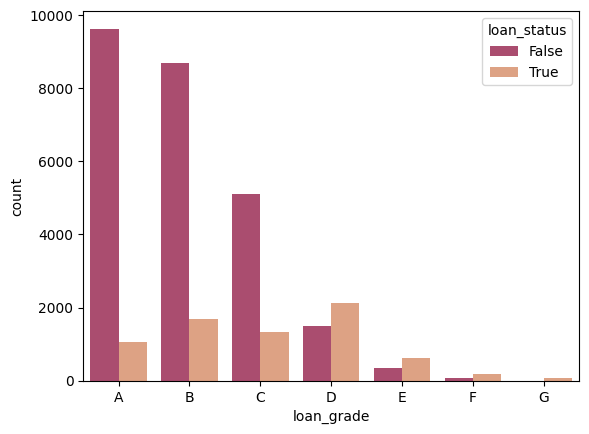

In [45]:
sns.countplot(x="loan_grade", hue="loan_status", data=df_clean, order=sorted(df_clean["loan_grade"].unique()), palette=[colors[5], colors[11]])

On this plot, there is a noticeable change in the default ratios of the different loan grades. It is apparent that in line with possible expectations, higher risk grades go hand in hand with higher default rates. Although the data seems to follow this pattern through all grades, as the size of the groups decrease, so does the certainty of the assumption. It is worth noting though, that even though group 'D' contains less data than the preceding grades, it contains more defaulters not just proportionally but numerically as well, supporting the pattern of higher default rates in higher risk categories. 

Considering that loan grades are determined at the time of the loan request and defaulting is confirmed by the failure of the repayment during the loan term, this finding suggests that the method chosen to categorize clients by risk was fairly successful and may hold predictive value of future defaults. With follow-up inspection it is possible not only to gain information about the method's reliability but also to fine-tune it or compare it to other methods.

<Axes: xlabel='person_home_ownership', ylabel='count'>

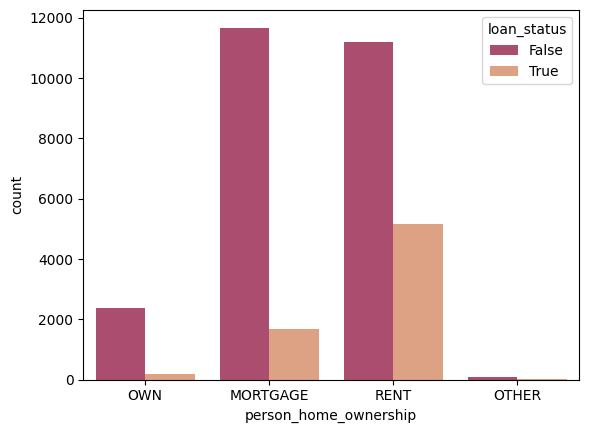

In [46]:
sns.countplot(x="person_home_ownership", hue="loan_status", data=df_clean, palette=[colors[5], colors[11]])

In accordance with the plot above, home renters seem to hold a higher risk of defaulting than owners and people with mortgage. Assuming that homeowners have lower living expenses than mortgage payers and rent payers, this correlation suggests that it is not the burden of housing costs that play a differentiating factor in defaulting. While keeping in mind that the 'OWN' category is too small to be certain, the difference between the 'MORTGAGE' and 'RENT' groups alone is consistent with this pattern.

# 6. <a id='toc6_'></a>[Summary: EDA findings](#toc0_)

## 6.1. <a id='toc6_1_'></a>[Predictive value and optimization potential of loan grades](#toc0_)



Loan grade is strongly associated with default status, prior default history and interest rates. Default rates rise across higher-risk grades, which suggests that grades capture risk-related information, and hold value for prediction. 

Interest rates (while relating to loan grades) differ by default status as well, but the distributions overlap, therefore this association is less pronounced than the interest rate differences across loan grades, so interest rate alone does not clearly separate defaulters from non-defaulters. Assuming that interest rates were offered with loan-related risk in mind, potential loan grade boundary refinement could have an effect on interest rate assignment strategy as well.

There is opportunity in investigating the optimization of loan grades based on other factors, for example the ones that differentiate default rate as well. Optimized loan grades can be useful for identifying risk more precisely and driving risk exposure balancing decisions.

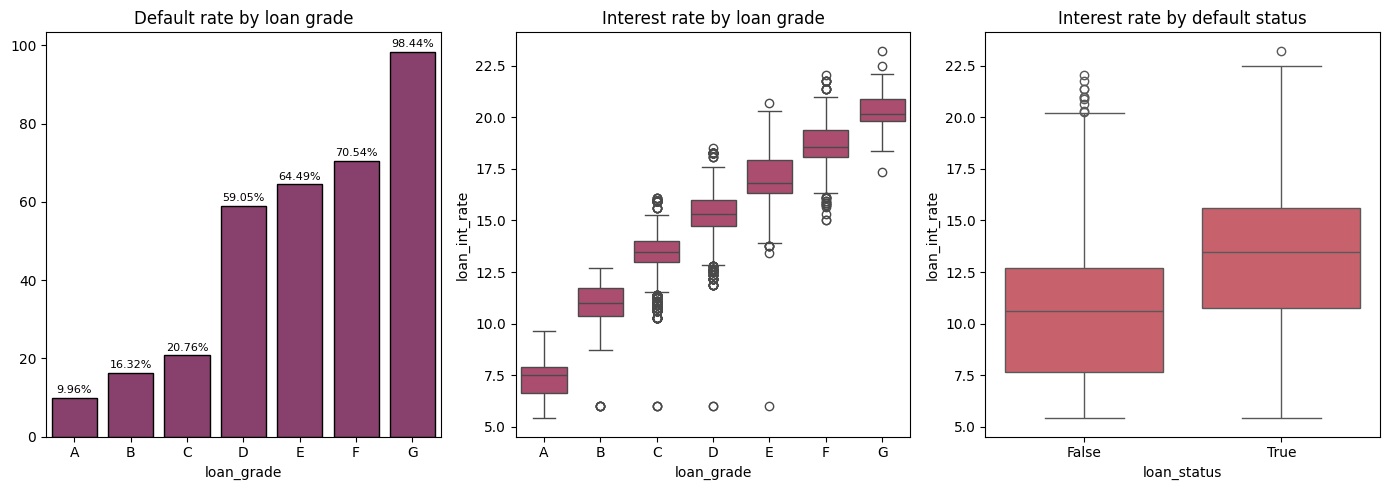

In [84]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

ax1 = axes[0]
default_grade_group = df_clean.groupby("loan_grade")["loan_status"].mean().mul(100).sort_values(ascending=False)
sns.barplot(x=default_grade_group.index, y=default_grade_group.values, color=colors[3], edgecolor="black", order=order, ax=ax1)
ax1.bar_label(ax1.containers[0], fontsize=8, padding=2, fmt="{:.2f}%")
ax1.set_title("Default rate by loan grade")

ax2 = axes[1]
sns.boxplot(data=df_clean, x="loan_grade", y="loan_int_rate", order=order, color=colors[5], ax=ax2)
ax2.set_title("Interest rate by loan grade")

ax3 = axes[2]
sns.boxplot(data=df_clean, x=col, y="loan_int_rate", ax=ax3, color=colors[7])
ax3.set_title("Interest rate by default status")

plt.tight_layout()
plt.show()

## 6.2. <a id='toc6_2_'></a>[Default rate differentiating factors and their implications](#toc0_)

Higher loan-to-income ratios are more common among defaulters, while income alone is also associated with default status, which implies that financial profiles hold risk-related information. This supports investigating the effect of loan burden on a monthly basis and suggests that there is potential in gathering corresponding data.

Home ownership also seems to impact default rate, with an interesting finding that renters show higher default rates than mortgage holders. Although this finding may imply that default rate differences do not arise from the burden of housing costs alone, it could reflect other underlying financial attitudes worth investigating. 

Text(0.5, 1.0, 'Default rate by home ownership')

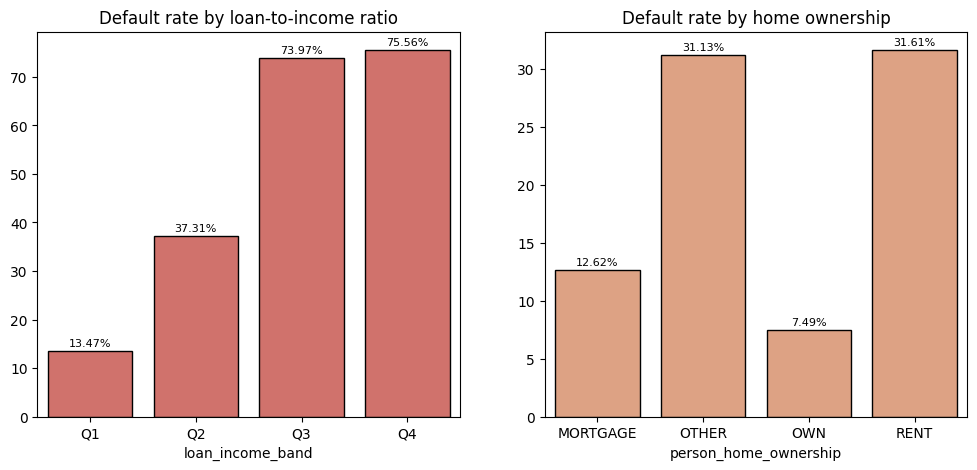

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax1 = axes[0]
df_clean["loan_income_band"] = pd.cut(df_clean["loan_pct_income"], bins=4, labels=["Q1", "Q2", "Q3", "Q4"], include_lowest=True)
loanpct_default_group = df_clean.groupby("loan_income_band", observed=False)["loan_status"].mean().mul(100).sort_index(ascending=False)

sns.barplot(x=loanpct_default_group.index, y=loanpct_default_group.values, color=colors[8], edgecolor="black", ax=ax1)
ax1.bar_label(ax1.containers[0], fontsize=8, padding=2, fmt="{:.2f}%")
ax1.set_title("Default rate by loan-to-income ratio")

ax2 = axes[1]
home_default_group = df_clean.groupby("person_home_ownership")["loan_status"].mean().mul(100)

sns.barplot(x=home_default_group.index, y=home_default_group.values, color=colors[11], edgecolor="black", ax=ax2)
ax2.bar_label(ax2.containers[0], fontsize=8, padding=2, fmt="{:.2f}%")
ax2.set_title("Default rate by home ownership")

## 6.3. <a id='toc6_3_'></a>[Next steps to identify actionable insights based on findings](#toc0_)

### 6.3.1. <a id='toc6_3_1_'></a>[Risk segmentation](#toc0_)

Risk segmentation can group applicants with similar observed risk profiles, helping reveal where current loan grades consistently over or underestimate default risk. Comparing outcomes across these segments can guide the refinement of grade boundaries with the help of other relevant factors that current grades may have neglected.

### 6.3.2. <a id='toc6_3_2_'></a>[Predictive ML model](#toc0_)

An ML model can complement the EDA by testing whether the observed relationships jointly help predict loan defaults, rather than assessing each factor in isolation. Having learnt from former defaults, the model can quickly turn data into a prediction by evaluating all relevant relationships parallelly.
If validated on a separate dataset, the predictions may support more consistent risk assessment and be used to inform human decision-making.

The data will need to be prepared specifically for the model by handling missing values, adding a missingness flag where it counts, transforming outliers and balancing underrepresented values.

## 6.4. <a id='toc6_4_'></a>[Limitations](#toc0_)

### 6.4.1. <a id='toc6_4_1_'></a>[Missing context and cardinality](#toc0_)

After looking at the variables and correlations at hand, we can tell that the dataset does not contain sufficient information to enable a deeper analysis with essential metrics (e.g. loan burden, expected return). Missing context includes demographic data like credit score, monthly repayment amount or loan-related data like term. It is also apparent, that the dataset does not contain all variables that played a role in assigning loan grades. 

Additionally, there are variables that lack potentially valuable information due to low cardinality. An example for this could be the cb_person_default_on_file column which tells whether the person has defaulted before, without detailing when or how many times. Higher cardinality data would be preferred, as it could always be binned or simplified while allowing for a more accurate analysis. 

### 6.4.2. <a id='toc6_4_2_'></a>[Survivorship bias](#toc0_)

Another limitation to mention is that the dataset is restricted to approved loans, without information about applicant population. This results in riskier groups being underrepresented and the dataset becoming more biased towards approved applicants.